# BC02 — Partie 2 | Analyse exploratoire et statistiques

**Question métier :** le montant net moyen par ligne de vente diffère-t-il entre les ventes avec code promotionnel et celles sans code ? Les données sont observationnelles : vous ne chercherez **pas** à prouver un effet causal.

## Étape 0 — Chargement

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np

def trouver_donnees():
    bases = [Path.cwd(), Path.cwd().parent, Path('/content'), Path('/content/CycleNova_Entrainement_RNCP38616')]
    for base in bases:
        for d in (base / 'DONNEES', base / 'CycleNova_Entrainement_RNCP38616' / 'DONNEES'):
            if (d / 'ventes.csv').is_file() and (d / 'produits.csv').is_file() and (d / 'prix_concurrents.csv').is_file():
                return d
    archive = Path('/content/CycleNova_Entrainement_RNCP38616.zip')
    if archive.exists():
        import zipfile
        with zipfile.ZipFile(archive) as z:
            z.extractall('/content')
        return trouver_donnees()
    raise FileNotFoundError('Dossier DONNEES absent. Consultez LISEZMOI.md et conservez la structure des dossiers.')

DATA = trouver_donnees()
produits = pd.read_csv(DATA / 'produits.csv')
ventes = pd.read_csv(DATA / 'ventes.csv')
prix_concurrents = pd.read_csv(DATA / 'prix_concurrents.csv')
print(f'Données chargées : produits={len(produits)}, ventes={len(ventes)}, prix_concurrents={len(prix_concurrents)}')

Données chargées : produits=65, ventes=3005, prix_concurrents=2818


## Étape 1 — Découverte de la donnée

1. Décrivez la granularité et le sens de chaque colonne.
2. Affichez dimensions, types, valeurs manquantes, doublons et distributions.
3. Identifiez des valeurs invalides ; définissez une règle cohérente pour les exclure ou les corriger.

In [2]:
# Dimensions et types
print("Dimensions ventes :", ventes.shape)
display(ventes.dtypes.to_frame("type"))

# Valeurs manquantes
display(ventes.isna().sum().to_frame("nb_manquants"))

# Doublons
print("Lignes entièrement dupliquées :", ventes.duplicated().sum())
print("id_vente en double :", ventes["id_vente"].duplicated().sum())

# Distributions des variables numériques
display(ventes[["quantite", "prix_unitaire", "taux_remise", "retour"]].describe())

# Modalités des variables catégorielles
for col in ["code_promo", "canal", "retour", "taux_remise"]:
    print(f"\n{col} :")
    print(ventes[col].value_counts(dropna=False).sort_index())

# Valeurs invalides selon les règles métier
ids_catalogue = produits["id_produit"].unique()
print("\nid_produit manquant :", ventes["id_produit"].isna().sum())
print("id_produit inconnu  :", (ventes["id_produit"].notna() & ~ventes["id_produit"].isin(ids_catalogue)).sum())
print("quantite <= 0       :", (ventes["quantite"] <= 0).sum())
print("prix_unitaire <= 0  :", (ventes["prix_unitaire"] <= 0).sum())
print("remise hors [0;1]   :", (~ventes["taux_remise"].between(0, 1)).sum())


Dimensions ventes : (3005, 11)


,type
id_vente,str
date_commande,str
id_produit,str
quantite,int64
prix_unitaire,float64
taux_remise,float64
code_promo,str
canal,str
retour,float64
date_retour,str


,nb_manquants
id_vente,0
date_commande,0
id_produit,11
quantite,0
prix_unitaire,11
taux_remise,0
code_promo,2073
canal,8
retour,5
date_retour,2501


Lignes entièrement dupliquées : 5
id_vente en double : 5


,quantite,prix_unitaire,taux_remise,retour
count,3005.000000,2994.000000,3005.000000,3000.000000
mean,1.416306,59.687515,0.048586,0.170000
std,0.735762,36.782786,0.092515,0.379229
min,-2.000000,-15.000000,-0.200000,0.000000
25%,1.000000,30.685000,0.000000,0.000000
50%,1.000000,49.180000,0.000000,0.000000
75%,2.000000,77.700000,0.100000,0.000000
max,4.000000,174.130000,1.500000,2.000000



code_promo :
code_promo
CYCLE20     286
VELO10      646
NaN        2073
Name: count, dtype: int64

canal :
canal
Application     439
Marketplace     717
Site web       1841
NaN               8
Name: count, dtype: int64

retour :
retour
0.0    2494
1.0     502
2.0       4
NaN       5
Name: count, dtype: int64

taux_remise :
taux_remise
-0.20       4
 0.00    2068
 0.10     352
 0.15     291
 0.20     191
 0.25      95
 1.50       4
Name: count, dtype: int64

id_produit manquant : 11
id_produit inconnu  : 8
quantite <= 0       : 7
prix_unitaire <= 0  : 5
remise hors [0;1]   : 8


### Réponses — Étape 1

**1. Granularité et sens des colonnes** : une ligne de `ventes` = une vente d'un produit (clé `id_vente`).
- `date_commande` : date de la commande (ISO) ; `id_produit` : produit vendu (clé vers `produits`) ;
- `quantite` : nombre d'unités ; `prix_unitaire` : prix payé par unité avant remise (EUR) ; `taux_remise` : remise appliquée (fraction de 0 à 1) ;
- `code_promo` : code promotionnel utilisé (vide si aucun) ; `canal` : canal de vente (Site web, Marketplace, Application) ;
- `retour` : 1 si le produit a été retourné, 0 sinon ; `date_retour`, `motif_retour` : connus seulement après la commande.

**2. Audit** : 3 005 lignes, 11 colonnes. On relève 5 `id_vente` dupliqués, 11 `id_produit` manquants et 8 inconnus (`P9999`), 11 prix manquants, ainsi que des valeurs manquantes sur `canal` (8) et `retour` (5). `code_promo`, `date_retour` et `motif_retour` sont vides par construction quand il n'y a pas de code ou pas de retour : ce ne sont pas des anomalies.

**3. Valeurs invalides et règle retenue** : quantités ≤ 0 (7), prix ≤ 0 (5), remises hors [0 ; 1] (8, valeurs −0,20 et 1,50). Règle, identique au BC01 : **exclusion** de ces lignes, car aucune correction ne peut être justifiée par les données. Les valeurs invalides de `retour` et de `canal` n'entrent pas dans le calcul du montant : elles ne motivent pas d'exclusion pour cette analyse.

## Étape 2 — Préparation argumentée

1. Construisez `montant_net = quantite * prix_unitaire * (1 - taux_remise)` pour des lignes valides.
2. Définissez `avec_promo` à partir de `code_promo` non vide.
3. Écartez les doublons de ventes, les quantités/prix/remises invalides et les produits inexistants ; expliquez vos critères.
4. Décrivez l’effet des exclusions sur la taille de l’échantillon.

In [3]:
n_brut = len(ventes)

# 1) Doublons : une ligne par id_vente
df = ventes.drop_duplicates(subset="id_vente", keep="first")
n_dedup = len(df)

# 2) Produits manquants ou inconnus (catalogue dédoublonné)
catalogue = produits.drop_duplicates(subset="id_produit")[["id_produit", "categorie"]]
df = df[df["id_produit"].isin(catalogue["id_produit"])]
n_produit = len(df)

# 3) Quantités, prix, remises invalides
df = df[(df["quantite"] > 0) & (df["prix_unitaire"] > 0) & (df["taux_remise"].between(0, 1))]
n_final = len(df)

# Ajout de la catégorie (validate garantit qu'aucune ligne n'est dupliquée)
df = df.merge(catalogue, on="id_produit", how="left", validate="many_to_one")

# Variables d'analyse
df["montant_net"] = df["quantite"] * df["prix_unitaire"] * (1 - df["taux_remise"])
df["avec_promo"] = df["code_promo"].notna() & (df["code_promo"].astype(str).str.strip() != "")

# Effet des exclusions
print(f"Lignes brutes                  : {n_brut}")
print(f"Après dédoublonnage            : {n_dedup}  (-{n_brut - n_dedup})")
print(f"Après filtre produit           : {n_produit}  (-{n_dedup - n_produit})")
print(f"Après filtre valeurs invalides : {n_final}  (-{n_produit - n_final})")
print(f"Total exclu : {n_brut - n_final} lignes ({100 * (n_brut - n_final) / n_brut:.1f} %)")

# Deux groupes indépendants
groupe_promo = df.loc[df["avec_promo"], "montant_net"]
groupe_sans  = df.loc[~df["avec_promo"], "montant_net"]
print(f"\nAvec code promo : {len(groupe_promo)} lignes | Sans code promo : {len(groupe_sans)} lignes")


Lignes brutes                  : 3005
Après dédoublonnage            : 3000  (-5)
Après filtre produit           : 2981  (-19)
Après filtre valeurs invalides : 2950  (-31)
Total exclu : 55 lignes (1.8 %)

Avec code promo : 915 lignes | Sans code promo : 2035 lignes


### Préparation — critères et effet sur l'échantillon

Mêmes règles qu'au BC01 : dédoublonnage par `id_vente`, exclusion des produits manquants ou inconnus, des quantités et prix ≤ 0 ou manquants, et des remises hors [0 ; 1].
`montant_net = quantite × prix_unitaire × (1 − taux_remise)` ; `avec_promo` = `code_promo` non vide.

Effet des exclusions : 3 005 → 3 000 (doublons) → 2 981 (produits) → **2 950 lignes** (valeurs invalides), soit 55 lignes exclues (1,8 %). L'échantillon reste largement suffisant ; les exclusions sont réparties sur les deux groupes et ne devraient pas biaiser la comparaison.
Groupes obtenus : **915 lignes avec code promo** et **2 035 sans code promo**.

## Étape 3 — Descriptif et graphiques

Calculez taille, moyenne, médiane, écart-type et IQR par groupe. Créez **au moins deux** visualisations appropriées (par exemple boxplot et histogramme). Expliquez la différence entre moyenne et médiane en présence de valeurs extrêmes.

,n,moyenne,mediane,ecart_type,q1,q3,IQR
avec_promo,,,,,,,
Sans code promo,2035,85.12,66.31,70.24,35.67,104.22,68.55
Avec code promo,915,71.61,55.06,59.12,29.81,89.01,59.20


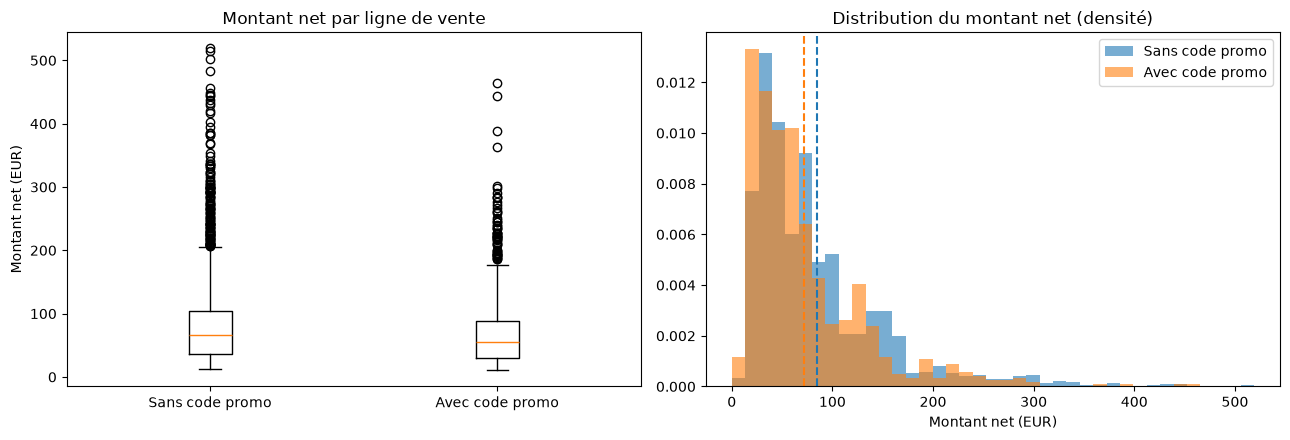

In [4]:
import matplotlib.pyplot as plt

# Statistiques par groupe
stats_groupes = df.groupby("avec_promo")["montant_net"].agg(
    n="count", moyenne="mean", mediane="median", ecart_type="std",
    q1=lambda x: x.quantile(0.25), q3=lambda x: x.quantile(0.75)
)
stats_groupes["IQR"] = stats_groupes["q3"] - stats_groupes["q1"]
stats_groupes.index = stats_groupes.index.map({False: "Sans code promo", True: "Avec code promo"})
display(stats_groupes.round(2))

# Graphique 1 : boxplot
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].boxplot([groupe_sans, groupe_promo], tick_labels=["Sans code promo", "Avec code promo"])
axes[0].set_title("Montant net par ligne de vente")
axes[0].set_ylabel("Montant net (EUR)")

# Graphique 2 : histogrammes superposés
bins = np.linspace(0, df["montant_net"].max(), 40)
axes[1].hist(groupe_sans, bins=bins, alpha=0.6, density=True, label="Sans code promo")
axes[1].hist(groupe_promo, bins=bins, alpha=0.6, density=True, label="Avec code promo")
axes[1].axvline(groupe_sans.mean(), linestyle="--", color="C0")
axes[1].axvline(groupe_promo.mean(), linestyle="--", color="C1")
axes[1].set_title("Distribution du montant net (densité)")
axes[1].set_xlabel("Montant net (EUR)")
axes[1].legend()
plt.tight_layout()
plt.show()


### Lecture des statistiques descriptives

| Groupe | n | Moyenne | Médiane | Écart-type | IQR |
|---|---|---|---|---|---|
| Sans code promo | 2 035 | 85,12 € | 66,31 € | 70,24 € | 68,56 € |
| Avec code promo | 915 | 71,61 € | 55,06 € | 59,12 € | 59,20 € |

Les lignes avec code promo ont un montant net moyen inférieur d'environ **13,5 €** (−16 %), et l'écart se retrouve aussi sur la médiane (−11 €).

**Moyenne vs médiane** : dans les deux groupes, la moyenne est nettement supérieure à la médiane. Les distributions sont **asymétriques à droite** : quelques lignes à fort montant (chaussures, quantités de 3 ou 4) tirent la moyenne vers le haut, alors que la médiane, qui ne dépend que du rang des valeurs, y est insensible. En présence de valeurs extrêmes, la médiane et l'IQR décrivent mieux la valeur « typique » et la dispersion que la moyenne et l'écart-type.

## Étape 4 — Hypothèse et test statistique

1. Énoncez H0 et H1 clairement pour les moyennes.
2. Justifiez le choix du test (par exemple t de Welch, avec réserves sur l’indépendance et la distribution).
3. Annoncez alpha = 0,05 avant de regarder la p-value.
4. Calculez la p-value et interprétez le résultat sans conclure à une causalité.

### Hypothèses

- **Indicateur** : montant net moyen par ligne de vente valide.
- **H0** : μ(avec code promo) = μ(sans code promo).
- **H1** : μ(avec code promo) ≠ μ(sans code promo) (test bilatéral).
- **Seuil annoncé avant le calcul** : α = 0,05.

**Choix du test : t de Welch.**
- On compare les **moyennes** de deux groupes **indépendants** (une ligne de vente n'appartient qu'à un seul groupe).
- Welch ne suppose **pas l'égalité des variances** ; ici les écarts-types diffèrent (70 contre 59 €) et les effectifs sont déséquilibrés.
- Les distributions ne sont pas normales (asymétrie à droite), mais avec 915 et 2 035 observations, le théorème central limite rend la distribution des moyennes approximativement normale : le test reste valable.

**Réserves** : l'indépendance n'est pas garantie à 100 %, car un même client peut avoir plusieurs lignes, et la table ne contient pas d'identifiant client pour le vérifier. On ajoute un test de Mann-Whitney (non paramétrique, sans hypothèse de normalité) comme contrôle de robustesse.

In [5]:
from scipy import stats

alpha = 0.05

# Test principal : t de Welch
t_stat, p_value = stats.ttest_ind(groupe_promo, groupe_sans, equal_var=False)
ecart = groupe_promo.mean() - groupe_sans.mean()
print(f"Écart des moyennes (promo - sans) : {ecart:.2f} €")
print(f"t de Welch = {t_stat:.3f} | p-value = {p_value:.2e}")
print("→ On rejette H0" if p_value < alpha else "→ On ne rejette pas H0", f"au seuil α = {alpha}")

# Contrôle de robustesse : Mann-Whitney
u_stat, p_mw = stats.mannwhitneyu(groupe_promo, groupe_sans, alternative="two-sided")
print(f"\nMann-Whitney : p-value = {p_mw:.2e}")

# Vérification complémentaire : le montant AVANT remise diffère-t-il ?
df["montant_avant_remise"] = df["quantite"] * df["prix_unitaire"]
avant_promo = df.loc[df["avec_promo"], "montant_avant_remise"]
avant_sans  = df.loc[~df["avec_promo"], "montant_avant_remise"]
t2, p2 = stats.ttest_ind(avant_promo, avant_sans, equal_var=False)
print(f"\nMontant AVANT remise : moyenne promo = {avant_promo.mean():.2f} € | sans = {avant_sans.mean():.2f} € | p-value = {p2:.3f}")

# Lien code promo / remise
display(pd.crosstab(df["code_promo"].fillna("aucun"), df["taux_remise"]))

Écart des moyennes (promo - sans) : -13.51 €
t de Welch = -5.408 | p-value = 7.09e-08
→ On rejette H0 au seuil α = 0.05

Mann-Whitney : p-value = 1.22e-09

Montant AVANT remise : moyenne promo = 84.38 € | sans = 85.12 € | p-value = 0.790


taux_remise,0.00,0.10,0.15,0.20,0.25
code_promo,,,,,
CYCLE20,0,0,0,187,95
VELO10,0,346,287,0,0
aucun,2035,0,0,0,0


### Interprétation

La p-value du t de Welch (≈ 7 × 10⁻⁸) est très inférieure à α = 0,05 : **on rejette H0**. Le montant net moyen par ligne diffère significativement entre les deux groupes (environ −13,5 € avec code promo). Le test de Mann-Whitney confirme le résultat (p ≈ 1 × 10⁻⁹) sans hypothèse de normalité.

Cela **ne prouve pas que les codes promo causent cette baisse** : les données sont observationnelles. La vérification complémentaire éclaire d'ailleurs le mécanisme : **avant remise**, les montants moyens sont quasi identiques (84,4 € contre 85,1 €, p ≈ 0,79). L'écart observé s'explique donc principalement par **la remise appliquée elle-même** (10 à 25 % pour toute ligne avec code), et non par des paniers différents.

## Étape 5 — Conclusion

Proposez une conclusion métier nuancée : tailles des groupes, différence observée, résultat du test, importance pratique de l’écart, limites et pistes de vérification.

### Conclusion métier

- **Tailles des groupes** : 915 lignes avec code promo contre 2 035 sans, sur 2 950 ventes valides (55 lignes exclues, 1,8 %).
- **Différence observée** : montant net moyen de 71,6 € avec code contre 85,1 € sans, soit environ −13,5 € (−16 %) ; l'écart se retrouve sur la médiane (55,1 € contre 66,3 €).
- **Résultat du test** : différence statistiquement significative au seuil de 5 % (t de Welch, p ≈ 7 × 10⁻⁸), confirmée par Mann-Whitney.
- **Importance pratique** : l'écart est réel et non négligeable, mais il correspond essentiellement au **coût de la remise** : avant remise, les paniers sont équivalents. Les codes promo ne semblent donc **pas associés à des paniers plus importants** : sur cet indicateur, ils réduisent le revenu par ligne sans contrepartie visible.
- **Limites** : données observationnelles (pas de causalité) ; indépendance non vérifiable sans identifiant client ; on ne mesure pas l'effet des promos sur le **nombre** de ventes ni sur l'acquisition de nouveaux clients, qui pourraient justifier leur coût.
- **Pistes de vérification** : comparer le volume de ventes en période promotionnelle, analyser par catégorie et par canal, distinguer les codes VELO10 et CYCLE20, et idéalement mener un **test A/B** (codes attribués aléatoirement) pour mesurer un effet causal.